In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [2]:
import os
import struct
import numpy as np
import torch

def read_images(path):
    with open(path, "rb") as f:
        magic, count, rows, cols = struct.unpack(">IIII", f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
        return data.reshape(count, 1, rows, cols).copy()

def read_labels(path):
    with open(path, "rb") as f:
        magic, count = struct.unpack(">II", f.read(8))
        return np.frombuffer(f.read(), dtype=np.uint8).copy()

# Find MNIST files in Kaggle Input
paths = {}
for root, dirs, files in os.walk("/kaggle/input"):
    for file in files:
        if file in [
            "train-images.idx3-ubyte",
            "train-labels.idx1-ubyte",
            "t10k-images.idx3-ubyte",
            "t10k-labels.idx1-ubyte"
        ]:
            paths[file] = os.path.join(root, file)

required = [
    "train-images.idx3-ubyte",
    "train-labels.idx1-ubyte",
    "t10k-images.idx3-ubyte",
    "t10k-labels.idx1-ubyte"
]

missing = [f for f in required if f not in paths]
if missing:
    raise FileNotFoundError(
        f"Missing MNIST files: {missing}. Check Kaggle Input."
    )

# Load and normalize images
X_train = torch.tensor(
    read_images(paths["train-images.idx3-ubyte"]),
    dtype=torch.float32
) / 255.0

y_train = torch.tensor(
    read_labels(paths["train-labels.idx1-ubyte"]),
    dtype=torch.long
)

X_test = torch.tensor(
    read_images(paths["t10k-images.idx3-ubyte"]),
    dtype=torch.float32
) / 255.0

y_test = torch.tensor(
    read_labels(paths["t10k-labels.idx1-ubyte"]),
    dtype=torch.long
)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)
print("Device:", device)

Training images: torch.Size([60000, 1, 28, 28])
Testing images: torch.Size([10000, 1, 28, 28])
Device: cuda


In [3]:
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score

# Prepare the dataset
train_data = TensorDataset(
    X_train.reshape(-1, 784), y_train
)
test_data = TensorDataset(
    X_test.reshape(-1, 784), y_test
)

train_loader = DataLoader(
    train_data, batch_size=128, shuffle=True
)
test_loader = DataLoader(
    test_data, batch_size=256
)

# Build ANN model
ann_model = nn.Sequential(
    nn.Linear(784, 256),
    nn.ReLU(),
    nn.Linear(256, 128),
    nn.ReLU(),
    nn.Linear(128, 10)
).to(device)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(
    ann_model.parameters(), lr=0.001
)

# Train the model
for epoch in range(5):
    ann_model.train()
    total_loss = 0

    for images, labels in train_loader:
        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()
        outputs = ann_model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(
        f"Epoch {epoch + 1}/5, "
        f"Loss: {total_loss / len(train_loader):.4f}"
    )

# Evaluate model
ann_model.eval()
predictions = []

with torch.no_grad():
    for images, _ in test_loader:
        outputs = ann_model(images.to(device))
        predictions.extend(
            outputs.argmax(dim=1).cpu().numpy()
        )

accuracy = accuracy_score(
    y_test.numpy(), predictions
)

print(f"\nANN Test Accuracy: {accuracy * 100:.2f}%")

# Save model
torch.save(
    ann_model.state_dict(),
    "/kaggle/working/mnist_ann.pth"
)

print("ANN model saved successfully!")

Epoch 1/5, Loss: 0.3455
Epoch 2/5, Loss: 0.1347
Epoch 3/5, Loss: 0.0876
Epoch 4/5, Loss: 0.0625
Epoch 5/5, Loss: 0.0463

ANN Test Accuracy: 97.60%
ANN model saved successfully!


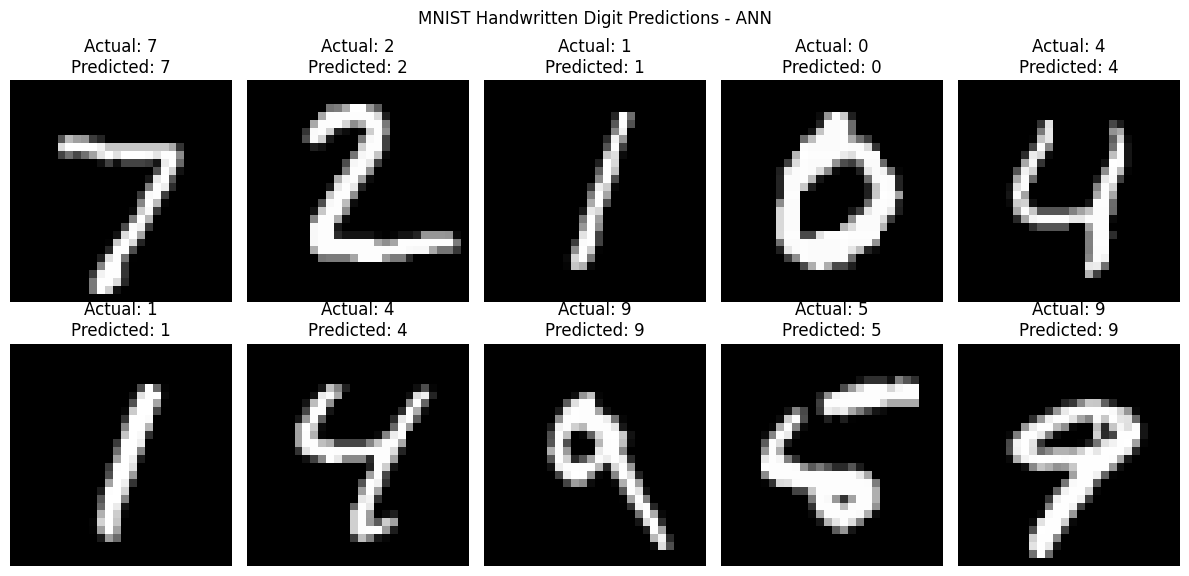

In [4]:
import matplotlib.pyplot as plt
import torch

# Display sample test images and ANN predictions
ann_model.eval()

fig, axes = plt.subplots(2, 5, figsize=(12, 6))

with torch.no_grad():
    for i, ax in enumerate(axes.flat):
        image = X_test[i]
        inputs = image.reshape(1, 784).to(device)

        prediction = ann_model(inputs).argmax(dim=1).item()
        actual = y_test[i].item()

        ax.imshow(image.squeeze().cpu().numpy(), cmap="gray")
        ax.set_title(
            f"Actual: {actual}\nPredicted: {prediction}"
        )
        ax.axis("off")

plt.suptitle("MNIST Handwritten Digit Predictions - ANN")
plt.tight_layout()
plt.show()

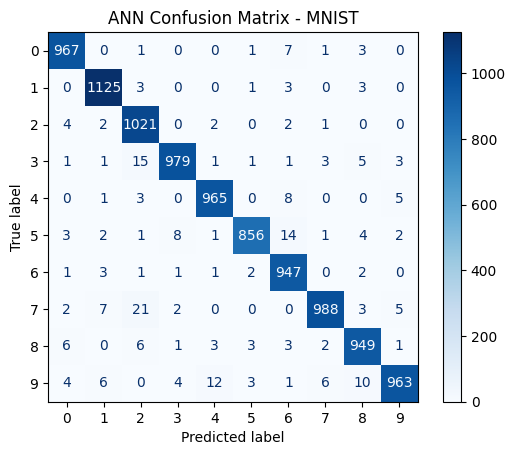

In [5]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

ConfusionMatrixDisplay.from_predictions(
    y_test.numpy(),
    predictions,
    labels=list(range(10)),
    display_labels=list(range(10)),
    cmap="Blues"
)

plt.title("ANN Confusion Matrix - MNIST")
plt.show()

In [6]:
print("Project: MNIST Handwritten Digit Classification")
print("Model: Artificial Neural Network (ANN)")
print("Training images:", len(X_train))
print("Testing images:", len(X_test))
print(f"Test Accuracy: {accuracy * 100:.2f}%")
print("Saved model: mnist_ann.pth")

Project: MNIST Handwritten Digit Classification
Model: Artificial Neural Network (ANN)
Training images: 60000
Testing images: 10000
Test Accuracy: 97.60%
Saved model: mnist_ann.pth


In [7]:
import os
import gzip
import struct
import torch

def read_images(path):
    with open(path, "rb") as f:
        magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
        data = f.read()
    images = torch.frombuffer(bytearray(data), dtype=torch.uint8)
    return images.reshape(num, 1, rows, cols).float() / 255.0

def read_labels(path):
    with open(path, "rb") as f:
        magic, num = struct.unpack(">II", f.read(8))
        data = f.read()
    return torch.frombuffer(bytearray(data), dtype=torch.uint8).long()

# Find MNIST files in Kaggle
base_path = "/kaggle/input"
files = {}

for root, dirs, filenames in os.walk(base_path):
    for filename in filenames:
        if filename in [
            "train-images.idx3-ubyte",
            "train-labels.idx1-ubyte",
            "t10k-images.idx3-ubyte",
            "t10k-labels.idx1-ubyte"
        ]:
            files[filename] = os.path.join(root, filename)

X_train = read_images(files["train-images.idx3-ubyte"])
y_train = read_labels(files["train-labels.idx1-ubyte"])
X_test = read_images(files["t10k-images.idx3-ubyte"])
y_test = read_labels(files["t10k-labels.idx1-ubyte"])

print("Training images:", X_train.shape)
print("Testing images:", X_test.shape)

Training images: torch.Size([60000, 1, 28, 28])
Testing images: torch.Size([10000, 1, 28, 28])


Training SVM model...
Training completed!

SVM Test Accuracy: 97.24%

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.99      0.98       980
           1       0.98      0.99      0.99      1135
           2       0.97      0.97      0.97      1032
           3       0.97      0.98      0.97      1010
           4       0.96      0.97      0.97       982
           5       0.98      0.96      0.97       892
           6       0.98      0.98      0.98       958
           7       0.97      0.96      0.97      1028
           8       0.97      0.97      0.97       974
           9       0.97      0.95      0.96      1009

    accuracy                           0.97     10000
   macro avg       0.97      0.97      0.97     10000
weighted avg       0.97      0.97      0.97     10000



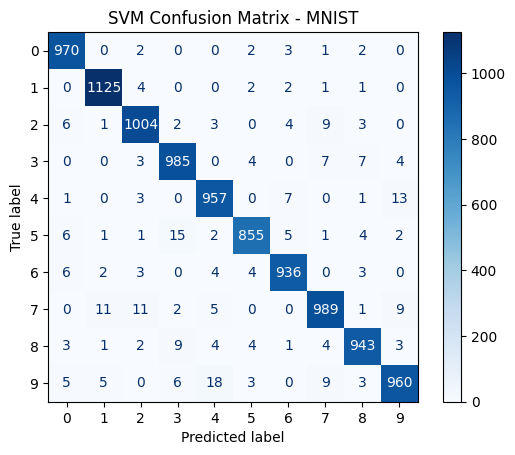

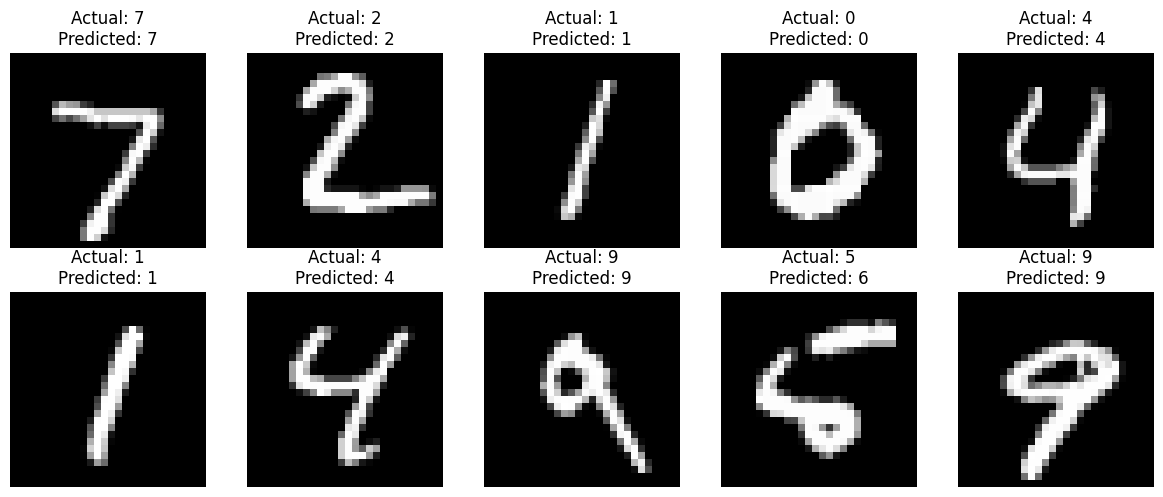

SVM model saved successfully!


In [8]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import joblib

from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report
from sklearn.metrics import ConfusionMatrixDisplay

# 1. Prepare MNIST dataset
X_train_svm = X_train.reshape(len(X_train), 784).cpu().numpy()
X_test_svm = X_test.reshape(len(X_test), 784).cpu().numpy()

y_train_svm = y_train.cpu().numpy()
y_test_svm = y_test.cpu().numpy()

# 2. Create SVM model
svm_model = SVC(kernel="rbf", C=5, gamma="scale")

# 3. Train model
print("Training SVM model...")
svm_model.fit(X_train_svm[:15000], y_train_svm[:15000])
print("Training completed!")

# 4. Predict test images
svm_predictions = svm_model.predict(X_test_svm)

# 5. Evaluate model
svm_accuracy = accuracy_score(y_test_svm, svm_predictions)

print(f"\nSVM Test Accuracy: {svm_accuracy * 100:.2f}%")
print("\nClassification Report:")
print(classification_report(y_test_svm, svm_predictions))

# 6. Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test_svm, svm_predictions, cmap="Blues"
)
plt.title("SVM Confusion Matrix - MNIST")
plt.show()

# 7. Display sample images
fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):
    ax.imshow(X_test[i, 0].cpu().numpy(), cmap="gray")
    ax.set_title(
        f"Actual: {y_test_svm[i]}\nPredicted: {svm_predictions[i]}"
    )
    ax.axis("off")

plt.tight_layout()
plt.show()

# 8. Save trained model
joblib.dump(svm_model, "/kaggle/working/mnist_svm.pkl")
print("SVM model saved successfully!")